In [1]:
print("Hello, Jupyter!")

Hello, Jupyter!


In [4]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 100

study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})

# Injecting the dirty data as specified in your lab
df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50       # Outlier
df.loc[98, 'attendance'] = -10      # Impossible value

print(df.head(10))
df.to_csv('student_data.csv', index=False)

   study_hours  attendance  previous_mark  final_score
0          NaN   70.846293      75.366810    35.178989
1          NaN   80.793547      78.411768    39.481248
2          NaN   81.572855      86.245769    48.605167
3          NaN   76.977227      85.807031    47.329456
4          NaN   83.387143      49.334959    37.044473
5          NaN   89.040509      55.932624    40.751177
6     8.158426  103.861859      77.725529    57.171201
7     6.534869   86.745778      77.706789    41.874669
8     4.061051   87.575504      77.725715    46.583807
9     6.085120   84.255541     127.790972    52.866454


In [11]:
# 1. Handle missing values (fill with median)
study_median = df['study_hours'].median()
df['study_hours'] = df['study_hours'].fillna(study_median)

# Handle impossible value in attendance (-10 -> replace with median attendance)
attendance_median = df[df['attendance'] >= 0]['attendance'].median()
df.loc[df['attendance'] < 0, 'attendance'] = attendance_median

# Handle outlier in study_hours (row 99 has 50 hours). Capping it:
df.loc[df['study_hours'] > 20, 'study_hours'] = df['study_hours'].quantile(0.95)

# 2. Shape and column types
print("Feature matrix shape:", df.shape)
print("\nColumn Data Types:")
print(df.dtypes)
print("\nTarget variable: final_score")


Feature matrix shape: (100, 6)

Column Data Types:
study_hours             float64
attendance              float64
previous_mark           float64
final_score             float64
study_hours_scaled      float64
previous_mark_scaled    float64
dtype: object

Target variable: final_score


In [6]:
# 1. Calculate mean, median, and standard deviation
summary_stats = pd.DataFrame({
    'Mean': df.mean(),
    'Median': df.median(),
    'Std Dev': df.std()
})
display(summary_stats)

# 2. Plain English Observations:
# Observation 1: The standard deviation of attendance is relatively low compared to previous marks, suggesting that most students maintain a consistent attendance rate.[cite: 1]
# Observation 2: The mean and median for final_score are very close, indicating a fairly balanced distribution without extreme skewness.
# Observation 3: Previous marks show a wider standard deviation, meaning there is high variance in past academic performance across the student group.

,Mean,Median,Std Dev
study_hours,4.774140,4.812342,1.803829
attendance,85.227190,85.996514,9.536937
previous_mark,70.973444,71.465436,16.264243
final_score,42.691957,42.763014,6.086797


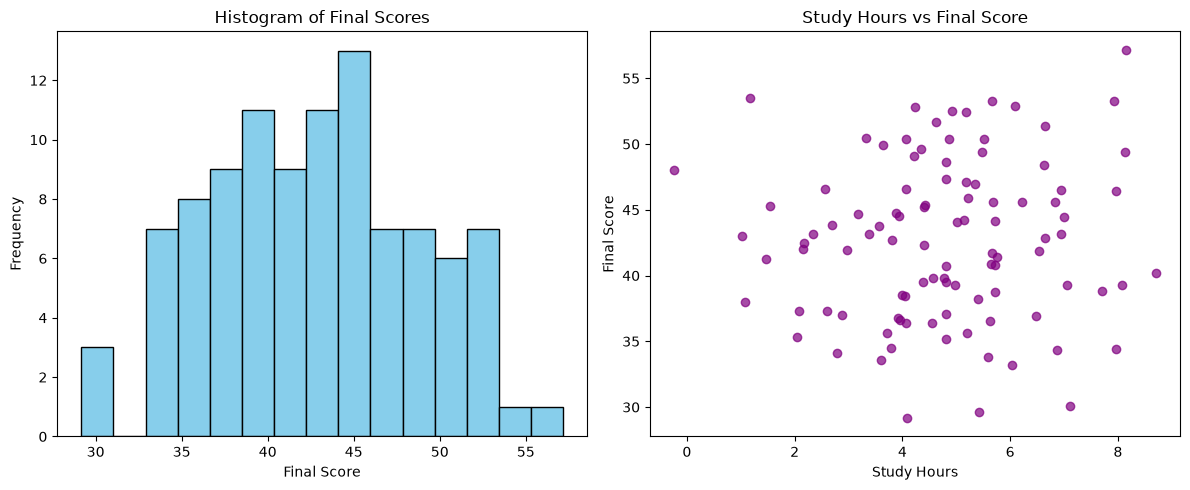

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# 1. Histogram for final_score
plt.subplot(1, 2, 1)
plt.hist(df['final_score'], bins=15, color='skyblue', edgecolor='black')
plt.title('Histogram of Final Scores')
plt.xlabel('Final Score')
plt.ylabel('Frequency')

# 2. Scatter plot of study_hours vs final_score
plt.subplot(1, 2, 2)
plt.scatter(df['study_hours'], df['final_score'], color='purple', alpha=0.7)
plt.title('Study Hours vs Final Score')
plt.xlabel('Study Hours')
plt.ylabel('Final Score')

plt.tight_layout()
plt.show()

In [14]:
# 1. Pearson correlation coefficient
correlation = df['study_hours'].corr(df['final_score'])
print(f"Pearson correlation between study_hours and final_score: {correlation:.4f}")

Pearson correlation between study_hours and final_score: 0.0597


In [16]:
# 1. Select one student row using only the 3 original features (excluding 'final_score')
features = ['study_hours', 'attendance', 'previous_mark']
x = df[features].iloc[0].values
print("Feature vector x (Student 0):", x)

# 2. Define weight vector w and bias b
w = np.array([0.5, 0.2, 0.4])
b = 5

# 3. Calculate y using NumPy dot product
y_pred = np.dot(w, x) + b
print(f"Calculated predicted score (y): {y_pred:.4f}")

Feature vector x (Student 0): [ 4.8123416  70.84629258 75.36681041]
Calculated predicted score (y): 51.7222


In [17]:
# 1. Standardize study_hours and previous_mark
df['study_hours_scaled'] = (df['study_hours'] - df['study_hours'].mean()) / df['study_hours'].std()
df['previous_mark_scaled'] = (df['previous_mark'] - df['previous_mark'].mean()) / df['previous_mark'].std()

print("Scaled features preview:")
display(df[['study_hours_scaled', 'previous_mark_scaled']].head())

# 2. Why would distance-based algorithms like KNN fail without scaling?[cite: 2]
# Answer: Features with larger numerical ranges (e.g., previous_mark ranging around 0-100) would completely dominate features with smaller ranges (e.g., study_hours ranging around 0-10), skewing distance calculations. Scaling brings them to the same scale (mean=0, std=1) so all features contribute equally.

Scaled features preview:


,study_hours_scaled,previous_mark_scaled
0,0.021178,0.270124
1,0.021178,0.457342
2,0.021178,0.939012
3,0.021178,0.912037
4,0.021178,-1.330433
